# PINN grid model v2-9 — physics fixes

Same data, features, transforms and training settings as the grid run of
`cotabato_new_slope_unit_v2-8.ipynb` (`combined_mapped.gpkg`, Makilala 25 m grid), with
three changes to the physics and a physics-only output head. Each is an opt-in flag on `train_model_rainfall_v3`; the
defaults still reproduce v2-8, so existing checkpoints are unaffected.

| Change | v2-8 grid model | v2-9 | Why |
|---|---|---|---|
| `geotech_exclude` | `Prc_mean` | `Prc_mean`, `Slope_mean`, `Elev_mean`, `BUK_mean` | φ was a function of slope (r = 0.82), so FOS = tan φ(slope) / tan(slope) was a free curve the physics did not constrain, and it did not transfer off Makilala. PGA is a separate input and was never seen by the geotech MLP. |
| Geotech MLP extra input (`GEOTECH_EXTRAS`) | — | `NDVI_mean` | Vegetation is the main per-cell control on shallow-soil cohesion (root reinforcement), and unlike the coarse SoilGrids layers NDVI varies cell to cell. It reaches the output only through c and φ. |
| `bulk_density_unit` | treated as kN/m³ | `cg/cm3` → γ = BD/100 × 9.81 | The grid's `BUK_mean` is SoilGrids bulk density (77–138 cg/cm³); read as kN/m³ γ was ~10× too large, which zeroed the cohesion term (median 0.0009) and shrank the pore-pressure term γ_w/γ ~10×. |
| `head` | `hybrid`: sigmoid(logit(physics_prob) + residual DNN), plus physics_prob and FOS as auxiliary outputs | `physics`: physics_prob is the prediction | The residual branch saw every feature (incl. Elev_mean) and scored AUC < 0.5; the prediction should come from the Newmark chain alone. Still output as `final_head`, so inference code is unchanged. |
| `wetness_saturation` | `sigmoid` → m ∈ [0.5, 1) | `clip` → m ∈ [0, 1] | The sigmoid floored every column at half-saturated, so m was nearly constant (median 0.52). |
| `cohesion_max_kpa` | unbounded relu | 30 → c = 30·sigmoid(x) kPa | With γ corrected the cohesion term is ~10× larger per kPa; the relu drifted to 55–70 kPa, so ac/PGA sat above the 0.75 clip for ~98% of cells (displacement pinned at 0.12 cm, AUC ≈ 0.52). |
| `acpg_clamp` | `hard`: clip(ac/PGA, 0.05, 0.75), ac = relu | `soft`: identity inside the bounds, rational tails outside, signed ac | The hard clip has zero gradient, so once cells saturated nothing could pull cohesion back. |
| `newmark_threshold` | `fixed`: sigmoid(D − 5 cm) | `learnable`: sigmoid(a·(ln D − ln D₀)), D₀ and a learned | With a fixed threshold the only way to lower the mean prediction toward the ~5% base rate was to raise c and φ everywhere (φ 28° → 53° in 8 epochs), which pinned cells at the displacement floor and erased their ranking. D₀ and a now carry the calibration. |

φ stays **unconstrained** (`InternalFrictionLayer` = sigmoid → 0–57°, off the geotechnical
Dense head), as in v2-8; cohesion is the same head output bounded to 0–30 kPa. With slope and elevation
removed from that head, φ can no longer be shaped into a function of slope; the
soil-conditioned alternative was tried and its 0–50 kPa "Undifferentiated" cohesion range
made FOS rank cells worse than slope alone.

Checkpoints and the per-fold transform manifests are written to `MODEL_SAVE_PATH` (the
manifests next to the models, so later runs cannot overwrite them in `feature_manifests/`).

In [1]:
import os
import sys
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.environ["TF_DETERMINISTIC_OPS"] = "1"

from py_files.helpers import set_seed
set_seed(42)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import tensorflow as tf

from py_files.data import preprocessing_v2
from py_files.train_rainfall_v3 import train_model_rainfall_v3
from py_files.helpers import add_soil_texture_index, add_soil_type_index_v3

# Cross-validation: "stratified" = random cells per fold (the original runs);
# "spatial" = whole BLOCK_SIZE_M x BLOCK_SIZE_M squares per fold (see section 2).
CV_MODE = None
BLOCK_SIZE_M = 2000

FILE_PATH = PROJECT_ROOT / "datasets/combined_mapped.gpkg"
# Spatial runs get their own folder so they never overwrite the stratified checkpoints.
MODEL_SAVE_PATH = PROJECT_ROOT / (
    "outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9"
    + (f"-spatial{BLOCK_SIZE_M // 1000}km" if CV_MODE == "spatial" else "")
)
MODEL_SAVE_PATH.mkdir(parents=True, exist_ok=True)

## 1. Load & preprocess (identical to v2-8)

In [2]:
COLUMNS_DROP = [
    'Landslide1', 'descriptio', 'sus_pinn_ground truth', 'ds',
    'cohesion', 'internal_friction', 'sus_pinn_landslide',
    'confusion', 'landslide_preds', 'landslide_probability',
    'Lithology', 'LITHO', 'Geomorphology', 'LITHODESC',
    'LITHO_2', 'LITHODESC_2', 'value',
]

df = gpd.read_file(FILE_PATH)
print(f"Raw dataset: {len(df):,} rows")
df, columns, numeric_cols, imputed_indicator_cols, imputation_medians = preprocessing_v2(
    df, columns_drop=COLUMNS_DROP, track_imputation=True,
)
print(f"Imputation indicators: {imputed_indicator_cols}")
print(columns)
print(df.shape)
print(df[["Clay_mean", "Silt_mean", "Sand_mean"]].describe())

df["soil_sum_content"] = df[["Clay_mean", "Silt_mean", "Sand_mean"]].sum(axis=1)

print(df[["soil_sum_content", "Clay_mean", "Silt_mean", "Sand_mean"]].describe())

# Physics inputs are used in real units by the FOS / Newmark / wetness layers, so the
# per-fold log/clip step inside train_model_rainfall_v3 must leave them alone.
PHYSICS_FEATURES = {
    'Slope_mean', 'BUK_mean', 'PGA2_max',
    'Prc_mean', 'ContributingFactor_mean',
    'SoilThc_mean',
    'LULC_majority',
}

df = add_soil_texture_index(df[columns].copy())
df = add_soil_type_index_v3(df)
print(f"{len(df):,} rows, {int(df['landslide'].sum()):,} landslides ({df['landslide'].mean():.2%})")
print(df["type"].value_counts().to_dict())

Raw dataset: 550,530 rows
  Preprocessing report:
    Starting rows:        550530  (landslide=15818)
    Dropped (Slope < 10): 259453  (landslide=845)
    Columns with nulls (model inputs):   {'BUK_mean': np.int64(1467), 'SoilThc_mean': np.int64(2181), 'PGA2_max': np.int64(2400), 'Clay_mean': np.int64(1467), 'Silt_mean': np.int64(1467), 'Sand_mean': np.int64(1467)}
    Median-imputed numeric (per col):    {'BUK_mean': 1467, 'SoilThc_mean': 2181, 'PGA2_max': 2400, 'Clay_mean': 1467, 'Silt_mean': 1467, 'Sand_mean': 1467}
    Missingness indicators added:        ['BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed']
    Dropped (NaN in ['landslide', 'type']): 0
    Final rows:           291077  (landslide=14973)
Imputation indicators: ['BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed']
['Slope_

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/geopandas/geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/geopandas/geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/geopandas/geodataframe.py:1819: SettingWithCopyWarning: 
A

291,077 rows, 14,973 landslides (5.14%)
{'Sandy Clay Loam': 216544, 'Undifferentiated': 74533}


In [3]:
MANIFEST_PATH = PROJECT_ROOT / "feature_manifests" / "v1_cotabato.json"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

PGA_COL = manifest["pga_col"]
selected_numerical = manifest["final_features"]["numerical"]
selected_categorical = manifest["final_features"]["categorical"]

# Inputs for the geotech MLP only (not in the v1 manifest). Appended after the manifest
# columns so the physics columns keep their numeric_cols positions.
GEOTECH_EXTRAS = []
geotech_extras = [c for c in GEOTECH_EXTRAS if c not in selected_numerical]
indicator_extras = [c for c in imputed_indicator_cols if c not in selected_numerical]
# soil_type_idx goes LAST: physics layers resolve inputs by numeric_cols position.
geotech_axis_extras = [] if "soil_type_idx" in selected_numerical else ["soil_type_idx"]
selected_numerical = selected_numerical + geotech_extras + indicator_extras + geotech_axis_extras
selected_feature_cols = selected_numerical + selected_categorical + ["landslide"]

print(f"PGA column:  {PGA_COL}")
print(f"Numerical:   {selected_numerical}")
print(f"Categorical: {selected_categorical}")

PGA column:  PGA2_max
Numerical:   ['Slope_mean', 'BUK_mean', 'Prc_mean', 'ContributingFactor_mean', 'SoilThc_mean', 'soil_texture_idx', 'PGA2_max', 'Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed', 'soil_type_idx']
Categorical: ['type']


## 2. Train v2-9

`CV_MODE` (cell 1) picks how the 5 folds are cut:

- **`stratified`** — each cell is assigned to a fold at random. A validation cell's
  25 m neighbours are almost always in training, and neighbours share nearly identical
  inputs and labels (one landslide covers many cells), so validation measures
  interpolation between known cells. It also rewards location shortcuts (elevation,
  coarse bulk-density pixels) because those hold inside the training area.
- **`spatial`** — the area is cut into `BLOCK_SIZE_M` squares, and every block goes
  whole to one fold (`StratifiedGroupKFold`, which also keeps the folds' landslide
  rates as even as the blocks allow). The model is validated on ground it has not seen
  nearby, which is what predicting the rest of North Cotabato requires.

Expect the spatial AUC to be lower; the gap between the two is how much the stratified
number owed to neighbouring cells.


Stratified random 5-fold CV:
  Fold 1 validation: 58,216 rows, 2,995 landslides (5.14%)
  Fold 2 validation: 58,216 rows, 2,995 landslides (5.14%)
  Fold 3 validation: 58,215 rows, 2,994 landslides (5.14%)
  Fold 4 validation: 58,215 rows, 2,994 landslides (5.14%)
  Fold 5 validation: 58,215 rows, 2,995 landslides (5.14%)
    log1p(Elev_mean)  skew was 1.39
    log1p(BUK_mean_was_imputed)  skew was 14.19
    log1p(SoilThc_mean_was_imputed)  skew was 11.54
    log1p(PGA2_max_was_imputed)  skew was 10.91
    log1p(Clay_mean_was_imputed)  skew was 14.19
    log1p(Silt_mean_was_imputed)  skew was 14.19
    log1p(Sand_mean_was_imputed)  skew was 14.19
    Clipped Elev_mean: [4.6834, 7.6721] (4658 values)
  Fold 1: wrote transform manifest -> /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json


/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:107: RuntimeWarning: overflow encountered in cast
  get_virtual_index=lambda n, quantiles: (n - 1) * quantiles,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4876: RuntimeWarning: overflow encountered in cast
  indexes_above_bounds = virtual_indexes >= valid_values_count - 1
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4781: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4782: RuntimeWarning: invalid value encountered in scalar multiply
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3

Epoch 1/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8568 - auc: 0.5749 - binary_io_u: 0.4630 - loss: 0.7013 - val_accuracy: 0.8752 - val_auc: 0.6971 - val_binary_io_u: 0.4982 - val_loss: 0.5562
Epoch 2/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9001 - auc: 0.6888 - binary_io_u: 0.5143 - loss: 0.6273 - val_accuracy: 0.9038 - val_auc: 0.7243 - val_binary_io_u: 0.5144 - val_loss: 0.5248
Epoch 3/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9071 - auc: 0.7274 - binary_io_u: 0.5217 - loss: 0.5956 - val_accuracy: 0.8956 - val_auc: 0.7533 - val_binary_io_u: 0.5128 - val_loss: 0.5148
Epoch 4/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9034 - auc: 0.7490 - binary_io_u: 0.5184 - loss: 0.5908 - val_accuracy: 0.9059 - val_auc: 0.7553 - val_binary_io_u: 0.5181 - val_loss: 0.5105
Epoch 5/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9042 - auc: 0.7597 - binary_io_u: 0.5221 - loss: 0.5823 - val_accuracy: 0.9063 - val_au

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:107: RuntimeWarning: overflow encountered in cast
  get_virtual_index=lambda n, quantiles: (n - 1) * quantiles,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4876: RuntimeWarning: overflow encountered in cast
  indexes_above_bounds = virtual_indexes >= valid_values_count - 1
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4781: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4782: RuntimeWarning: invalid value encountered in scalar multiply
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3

Epoch 1/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8150 - auc: 0.7118 - binary_io_u_1: 0.4625 - loss: 0.6924 - val_accuracy: 0.9047 - val_auc: 0.7180 - val_binary_io_u_1: 0.5197 - val_loss: 0.5330
Epoch 2/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8979 - auc: 0.7323 - binary_io_u_1: 0.5177 - loss: 0.6079 - val_accuracy: 0.8955 - val_auc: 0.7237 - val_binary_io_u_1: 0.5177 - val_loss: 0.5215
Epoch 3/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8960 - auc: 0.7388 - binary_io_u_1: 0.5197 - loss: 0.5977 - val_accuracy: 0.9059 - val_auc: 0.7405 - val_binary_io_u_1: 0.5220 - val_loss: 0.5146
Epoch 4/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8988 - auc: 0.7431 - binary_io_u_1: 0.5219 - loss: 0.5903 - val_accuracy: 0.9002 - val_auc: 0.7536 - val_binary_io_u_1: 0.5215 - val_loss: 0.5096
Epoch 5/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8964 - auc: 0.7567 - binary_io_u_1: 0.5204 - loss: 0.5836 - val_accurac

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:107: RuntimeWarning: overflow encountered in cast
  get_virtual_index=lambda n, quantiles: (n - 1) * quantiles,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4876: RuntimeWarning: overflow encountered in cast
  indexes_above_bounds = virtual_indexes >= valid_values_count - 1
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4781: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4782: RuntimeWarning: invalid value encountered in scalar multiply
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3

Epoch 1/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8582 - auc: 0.6543 - binary_io_u_2: 0.4853 - loss: 0.6806 - val_accuracy: 0.8939 - val_auc: 0.6826 - val_binary_io_u_2: 0.5080 - val_loss: 0.5559
Epoch 2/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8937 - auc: 0.6869 - binary_io_u_2: 0.5090 - loss: 0.6389 - val_accuracy: 0.8939 - val_auc: 0.7177 - val_binary_io_u_2: 0.5149 - val_loss: 0.5350
Epoch 3/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8944 - auc: 0.7155 - binary_io_u_2: 0.5160 - loss: 0.6096 - val_accuracy: 0.8860 - val_auc: 0.7362 - val_binary_io_u_2: 0.5147 - val_loss: 0.5241
Epoch 4/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8947 - auc: 0.7258 - binary_io_u_2: 0.5174 - loss: 0.5995 - val_accuracy: 0.9004 - val_auc: 0.7200 - val_binary_io_u_2: 0.5159 - val_loss: 0.5175
Epoch 5/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8961 - auc: 0.7246 - binary_io_u_2: 0.5174 - loss: 0.5892 - val_accurac

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:107: RuntimeWarning: overflow encountered in cast
  get_virtual_index=lambda n, quantiles: (n - 1) * quantiles,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4876: RuntimeWarning: overflow encountered in cast
  indexes_above_bounds = virtual_indexes >= valid_values_count - 1
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4781: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4782: RuntimeWarning: invalid value encountered in scalar multiply
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3

Epoch 1/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8986 - auc: 0.6761 - binary_io_u_3: 0.5009 - loss: 0.6523 - val_accuracy: 0.9083 - val_auc: 0.7181 - val_binary_io_u_3: 0.5238 - val_loss: 0.5374
Epoch 2/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9080 - auc: 0.7286 - binary_io_u_3: 0.5236 - loss: 0.6071 - val_accuracy: 0.8965 - val_auc: 0.7511 - val_binary_io_u_3: 0.5216 - val_loss: 0.5232
Epoch 3/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9033 - auc: 0.7556 - binary_io_u_3: 0.5238 - loss: 0.5956 - val_accuracy: 0.8966 - val_auc: 0.7706 - val_binary_io_u_3: 0.5215 - val_loss: 0.5139
Epoch 4/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8992 - auc: 0.7756 - binary_io_u_3: 0.5212 - loss: 0.5861 - val_accuracy: 0.9039 - val_auc: 0.7737 - val_binary_io_u_3: 0.5286 - val_loss: 0.5086
Epoch 5/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9032 - auc: 0.7769 - binary_io_u_3: 0.5255 - loss: 0.5798 - val_accurac

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:107: RuntimeWarning: overflow encountered in cast
  get_virtual_index=lambda n, quantiles: (n - 1) * quantiles,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4876: RuntimeWarning: overflow encountered in cast
  indexes_above_bounds = virtual_indexes >= valid_values_count - 1
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4781: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4782: RuntimeWarning: invalid value encountered in scalar multiply
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5,
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3

Epoch 1/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step - accuracy: 0.8846 - auc: 0.6528 - binary_io_u_4: 0.5020 - loss: 0.6708 - val_accuracy: 0.9015 - val_auc: 0.6697 - val_binary_io_u_4: 0.5131 - val_loss: 0.5582
Epoch 2/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8982 - auc: 0.6930 - binary_io_u_4: 0.5145 - loss: 0.6334 - val_accuracy: 0.8858 - val_auc: 0.7194 - val_binary_io_u_4: 0.5085 - val_loss: 0.5413
Epoch 3/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8960 - auc: 0.7105 - binary_io_u_4: 0.5161 - loss: 0.6124 - val_accuracy: 0.8904 - val_auc: 0.7317 - val_binary_io_u_4: 0.5149 - val_loss: 0.5208
Epoch 4/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8960 - auc: 0.7351 - binary_io_u_4: 0.5180 - loss: 0.5946 - val_accuracy: 0.9062 - val_auc: 0.7079 - val_binary_io_u_4: 0.5154 - val_loss: 0.5186
Epoch 5/200
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9001 - auc: 0.7481 - binary_io_u_4: 0.5192 - loss: 0.5863 - val_accurac

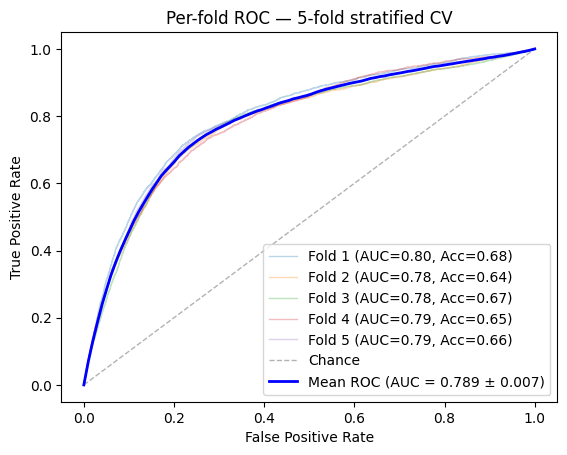


Per-fold OOF AUCs (Makilala, None CV): [np.float64(0.8018), np.float64(0.7818), np.float64(0.7821), np.float64(0.7879), np.float64(0.7903)]


In [4]:
# Physics fixes (see the table at the top). Everything else matches the v2-8 grid run.
PHYSICS_FIXES = dict(
    geotech_mode="unconstrained",
    geotech_exclude=("Prc_mean", "Slope_mean", "Elev_mean", "BUK_mean"),
    bulk_density_unit="cg/cm3",
    wetness_saturation="sigmoid",
    cohesion_max_kpa=30.0,
    acpg_clamp="soft",
    newmark_threshold="learnable",
)

# One block id per training row; preprocessing_v2 keeps the raw file's row index, so the
# geometry lines up through df.index (as in the OOF map below).
spatial_groups = None
if CV_MODE == "spatial":
    from py_files.data import spatial_block_ids
    cells = gpd.read_file(FILE_PATH, columns=[])
    spatial_groups = spatial_block_ids(cells.geometry.loc[df.index], BLOCK_SIZE_M)

oof_preds, fold_aucs = train_model_rainfall_v3(
    df,
    selected_numerical,
    selected_categorical,
    selected_feature_cols,
    PGA_COL,
    str(MODEL_SAVE_PATH),
    physics_features=PHYSICS_FEATURES,
    skew_threshold=1.0,
    clip_lower_pct=1,
    clip_upper_pct=99,
    transforms_dir=MODEL_SAVE_PATH,
    categorical_encoder='embedding',
    imputed_indicator_cols=imputed_indicator_cols,
    imputation_medians=imputation_medians,
    wetness_mode="rt_ratio",
    k_table="rawls",
    trainable_k=True,
    soil_axis="type",
    # recharge=3,
    # recharge_unit="mm/day",
    fos_thickness="soil_thickness",
    head="physics",
    spatial_groups=spatial_groups,
    **PHYSICS_FIXES,
)
print(f"\nPer-fold OOF AUCs (Makilala, {CV_MODE} CV): {[round(a, 4) for a in fold_aucs]}")
with open(MODEL_SAVE_PATH / "physics_fixes.json", "w") as f:
    json.dump({k: list(v) if isinstance(v, tuple) else v for k, v in PHYSICS_FIXES.items()}, f, indent=2)

### 2b. Susceptibility map — training area (out-of-fold)

Every cell is predicted by the fold model that did **not** train on it (`oof_preds`,
the `final_head` output), so this is the honest in-area map — not a map of the data the
model memorised. Uses `oof_preds` from the training cell, or `oof_preds.npy` from
`MODEL_SAVE_PATH` if the kernel was restarted (cell 1 of section 1 must still have run).


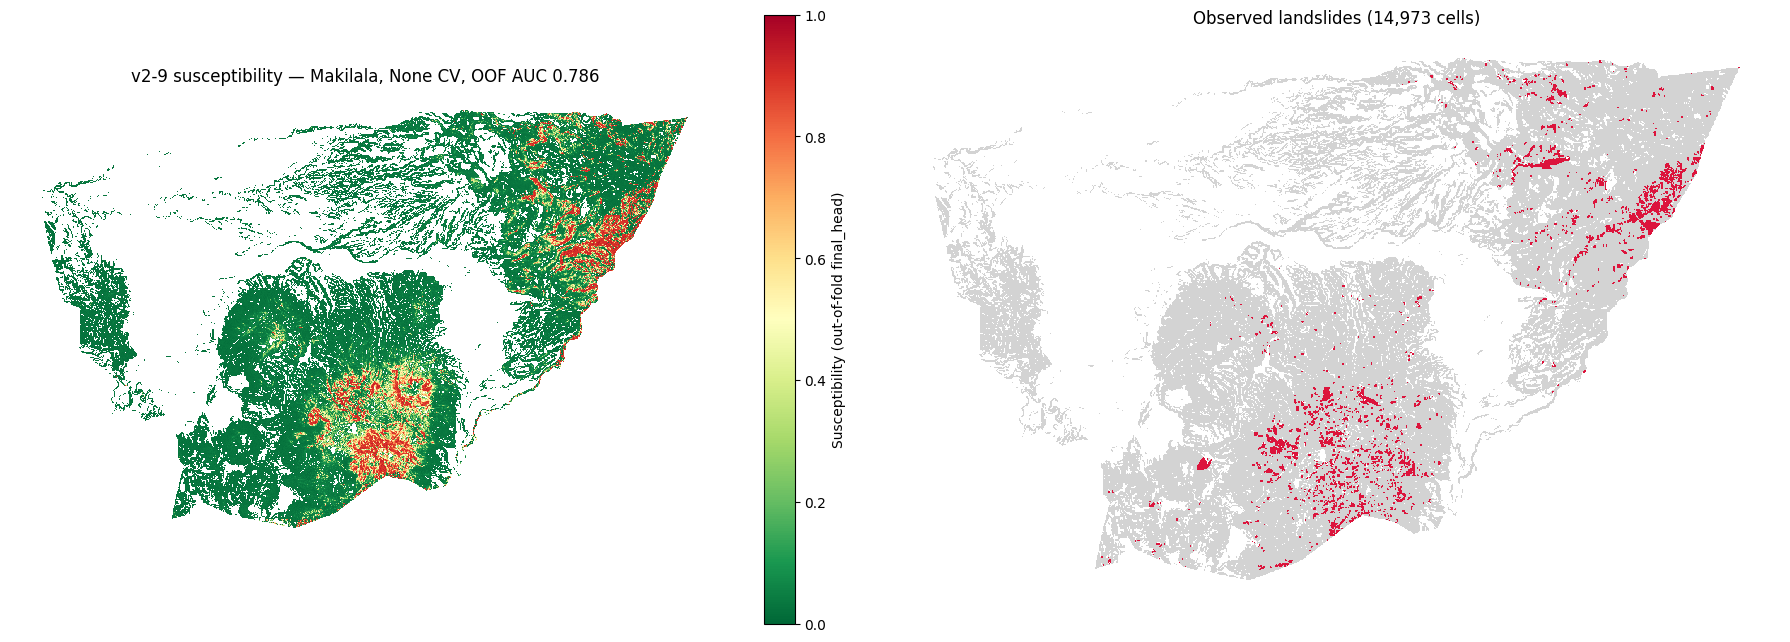

In [5]:
import matplotlib.colors as mcolors
from sklearn.metrics import roc_auc_score
oof = oof_preds if "oof_preds" in globals() else np.load(MODEL_SAVE_PATH / "oof_preds.npy")
oof = np.asarray(oof).ravel()
if len(oof) != len(df):
    raise ValueError(
        f"{len(oof):,} OOF predictions vs {len(df):,} training rows — re-run section 1 "
        "with the same settings the model was trained with."
    )

# preprocessing_v2 drops geometry but keeps the row index (filters by mask, no reset),
# so the raw file's geometry lines up through df.index.
cells = gpd.read_file(FILE_PATH, columns=[])
sus_map = gpd.GeoDataFrame(
    {"susceptibility": oof, "landslide": df["landslide"].to_numpy()},
    geometry=cells.geometry.loc[df.index].to_numpy(),
    crs=cells.crs,
)

norm = mcolors.Normalize(vmin=0.0, vmax=1.0)
fig, (ax_sus, ax_obs) = plt.subplots(1, 2, figsize=(18, 9), sharex=True, sharey=True)

sus_map.plot(column="susceptibility", cmap="RdYlGn_r", norm=norm, ax=ax_sus,
             edgecolor="none", antialiased=False)
fig.colorbar(plt.cm.ScalarMappable(cmap="RdYlGn_r", norm=norm), ax=ax_sus,
             shrink=0.7, label="Susceptibility (out-of-fold final_head)")
ax_sus.set_title(f"v2-9 susceptibility — Makilala, {CV_MODE} CV, OOF AUC {roc_auc_score(sus_map['landslide'], oof):.3f}")

sus_map.plot(color="lightgrey", ax=ax_obs, edgecolor="none", antialiased=False)
sus_map[sus_map["landslide"] == 1].plot(color="crimson", ax=ax_obs, edgecolor="none", antialiased=False)
ax_obs.set_title(f"Observed landslides ({int(sus_map['landslide'].sum()):,} cells)")

for ax in (ax_sus, ax_obs):
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(MODEL_SAVE_PATH / "susceptibility_map_oof.png", dpi=200, bbox_inches="tight")
plt.show()


### 2c. Which fold validated each cell

From `cv_folds.npy` (written by the training run). With spatial CV each fold is a set of
whole blocks; the table gives each fold's out-of-fold AUC, so a weak fold can be traced
to the part of the map it covers.


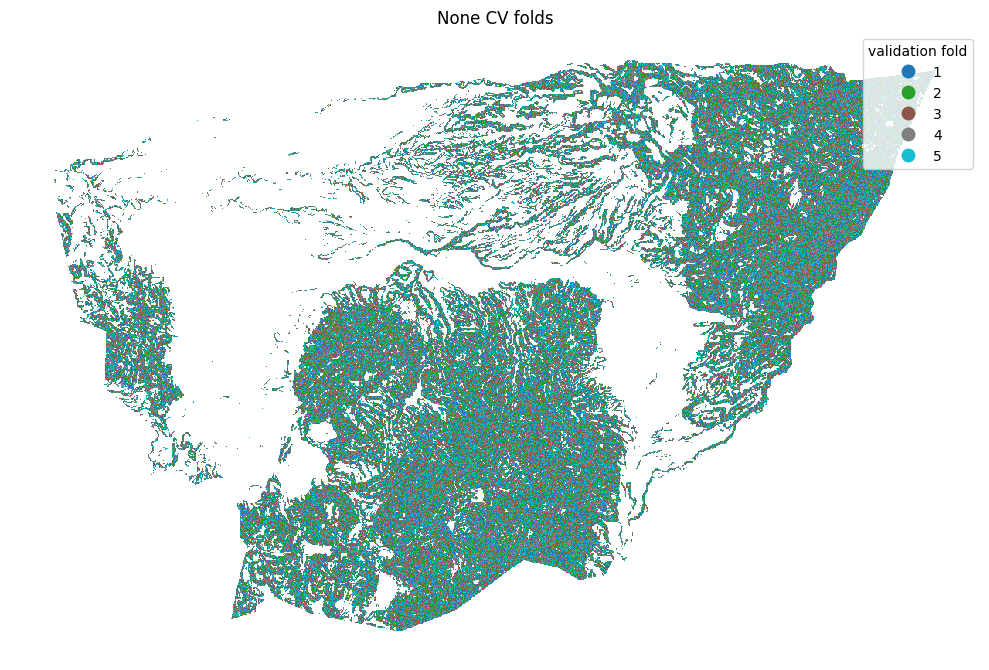

,cells,landslides,landslide_rate,oof_auc
fold,,,,
1,58216.0,2995.0,0.0514,0.8018
2,58216.0,2995.0,0.0514,0.7818
3,58215.0,2994.0,0.0514,0.7821
4,58215.0,2994.0,0.0514,0.7879
5,58215.0,2995.0,0.0514,0.7903


In [6]:
from py_files.train_rainfall_v3 import CV_FOLDS_FILENAME

cv_folds = np.load(MODEL_SAVE_PATH / CV_FOLDS_FILENAME)
if len(cv_folds) != len(sus_map):
    raise ValueError(f"{len(cv_folds):,} fold labels vs {len(sus_map):,} cells — re-run section 1")
fold_map = sus_map.assign(fold=cv_folds)

fig, ax = plt.subplots(figsize=(10, 9))
fold_map.plot(column="fold", categorical=True, cmap="tab10", legend=True, ax=ax,
              edgecolor="none", antialiased=False, legend_kwds={"title": "validation fold"})
ax.set_title(f"{CV_MODE} CV folds" + (f" ({BLOCK_SIZE_M} m blocks)" if CV_MODE == "spatial" else ""))
ax.set_axis_off()
fig.tight_layout()
fig.savefig(MODEL_SAVE_PATH / "cv_folds_map.png", dpi=200, bbox_inches="tight")
plt.show()

fold_table = fold_map.groupby("fold").apply(
    lambda g: pd.Series({
        "cells": len(g),
        "landslides": int(g["landslide"].sum()),
        "landslide_rate": g["landslide"].mean(),
        "oof_auc": roc_auc_score(g["landslide"], g["susceptibility"]),
    }),
    include_groups=False,
)
fold_table.round(4)


In [7]:
PHYSICS_FIXES = dict(
    geotech_mode="unconstrained",
    geotech_exclude=("Prc_mean", "Slope_mean"),
    bulk_density_unit="cg/cm3",
    wetness_saturation="clip",
    cohesion_max_kpa=30.0,
    acpg_clamp="soft",
    newmark_threshold="learnable",
)

## 3. Did the physics come back to life?

For each fold, on the training area (Makilala) and on the held-out LSI area (inventory
extent minus the Makilala training zone): AUC of each branch, the size of each FOS term,
and the learned geotechnical parameters. Compare with the v2-8 grid model (fold 1):
held-out `final_head` **0.534**, cohesion term **0.0009**, pore term **0.08**, m median
**0.52**, corr(φ, slope) **0.82**.

In [8]:
import rasterio
from shapely.geometry import box
from tensorflow.keras import Model

from py_files.data import dataframe_to_dataset
from py_files.GallenModel_v3 import BULK_UNIT_TO_KN_M3
from run_model_v3 import (
    build_model_inputs, find_transforms_manifest, load_and_preprocess,
    load_trained_model, replay_transforms,
)

LSI_PATH = Path("~/Downloads/LSI_NorthCotabato_10m (1).tif").expanduser()
TRAINING_ROI_PATH = PROJECT_ROOT / "datasets/roi/makilala_boundary.gpkg"
GRID_CELL_M = 25.0
DIAG_LAYERS = ["cohesion_layer", "internal_friction", "m_clip",
               "physics_prob"]
GAMMA_SCALE = BULK_UNIT_TO_KN_M3[PHYSICS_FIXES["bulk_density_unit"]]


def held_out_area():
    """nc_mapped cells inside the LSI extent and outside the Makilala training zone."""
    with rasterio.open(LSI_PATH) as lsi:
        extent = tuple(lsi.bounds)
    frame, _, _ = load_and_preprocess(str(PROJECT_ROOT / "datasets/nc_mapped.gpkg"), bbox=extent)
    centres = frame.geometry.centroid
    zone = gpd.read_file(TRAINING_ROI_PATH).to_crs(frame.crs).union_all().buffer(GRID_CELL_M * np.sqrt(2))
    keep = centres.within(box(*extent)) & ~centres.within(zone)
    return frame[keep]


def training_area():
    frame, _, _ = load_and_preprocess(str(FILE_PATH))
    return frame


AREAS = {"train (Makilala)": training_area(), "held-out (LSI area)": held_out_area()}
# The FOS divides by bulk density; nodata cells stored as 0 have no defined physics.
AREAS = {name: frame[frame["BUK_mean"] > 0] for name, frame in AREAS.items()}
for name, frame in AREAS.items():
    print(f"{name}: {len(frame):,} rows, {int(frame['landslide'].sum()):,} landslides")

train (Makilala): 286,274 rows, 14,403 landslides
held-out (LSI area): 414,406 rows, 5,975 landslides


In [9]:
from numpy import diag
from py_files.GallenModel_v3 import WetnessLayerDimensional
from scripts.predict_cianjur_v2_8 import FOLD
from sklearn.metrics import roc_auc_score

def diagnose_learned_model_weights(model):
    layer = next((l for l in model.layers if isinstance(l, WetnessLayerDimensional)), None)
    if layer is None:
        return
    print("Learned weights for WetnessLayerDimensional:")
    print(layer.get_weights())
    scaler = layer.lambda_min + (layer.lambda_max - layer.lambda_min) * tf.nn.sigmoid(layer.u_lambda)
    print(scaler)


def diagnose(fold, frame):
    path = MODEL_SAVE_PATH / f"fold-{fold}-model-v3.keras"
    model = load_trained_model(str(path))
    diagnose_learned_model_weights(model=model)
    extractor = Model(model.inputs, {n: model.get_layer(n).output for n in DIAG_LAYERS})
    feed = build_model_inputs(
        replay_transforms(frame, model, find_transforms_manifest(str(path))), model, pga_col=PGA_COL,
    )
    raw = extractor.predict(dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=8192), verbose=0)
    out = {k: np.asarray(v).reshape(len(feed), -1)[:, 0] for k, v in raw.items()}

    y = frame["landslide"].to_numpy().astype(int)
    theta = np.radians(frame["Slope_mean"].to_numpy())
    gamma = frame["BUK_mean"].to_numpy() * GAMMA_SCALE * 1000.0           # N/m^3
    thickness = np.maximum(frame["SoilThc_mean"].to_numpy(), 0.5)
    phi, m = out["internal_friction"], out["m_clip"]
    cohesion_term = out["cohesion_layer"] * 1000.0 / (gamma * thickness * np.sin(theta))
    pore_term = m * 9810.0 * np.tan(phi) / (gamma * np.tan(theta))
    return {
        "fold": fold,
        # "AUC final": roc_auc_score(y, out["final_head"]),
        "AUC physics": roc_auc_score(y, out["physics_prob"]),
        # "AUC -FOS": roc_auc_score(y, -out["fos_layer"]),
        "coh term": np.median(cohesion_term),
        "pore term": np.median(pore_term),
        "m median": np.median(m),
        "m p5-p95": f"{np.percentile(m, 5):.2f}-{np.percentile(m, 95):.2f}",
        "coh kPa": np.median(out["cohesion_layer"]),
        "phi deg": np.degrees(np.median(phi)),
        "corr(phi,slope)": np.corrcoef(phi, frame["Slope_mean"])[0, 1],
    }, out


FOLDS = [1, 2, 3, 4, 5]

result_diagnose = []
out = None

for f in FOLDS:
    result, out = diagnose(f, frame)
    result_diagnose.append(result)

diagnostics = pd.concat(
    {name: pd.DataFrame(result_diagnose).set_index("fold")
     for name, frame in AREAS.items()},
    names=["area"],
)
diagnostics.to_csv(MODEL_SAVE_PATH / "physics_diagnostics.csv")
pd.set_option("display.width", 200)
diagnostics.round(3)

print(pd.DataFrame(out))

  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2633, PGA2_max_was_imputed=0.0000
  Categorical 'type': 98.7% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']
  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold2.json (v1_cotabato_fold2): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mea

In [10]:
# Fold means. Slope-only reference = AUC of -tan(median phi)/tan(slope), i.e. what
# slope alone ranks like; v2-8's held-out final head (0.534) sat BELOW it (0.605).
numeric_diag = diagnostics.drop(columns=["m p5-p95"])
summary = numeric_diag.groupby(level="area").agg(["mean", "std"]).round(3)
for name, frame in AREAS.items():
    print(f"{name}: slope-only AUC {roc_auc_score(frame['landslide'], frame['Slope_mean']):.3f}")
summary

train (Makilala): slope-only AUC 0.750
held-out (LSI area): slope-only AUC 0.605


AUC physics        coh term        pore term        m median        coh kPa           phi deg        corr(phi,slope)       
                           mean    std     mean    std      mean    std     mean    std    mean    std       mean    std            mean    std
area                                                                                                                                           
held-out (LSI area)       0.575  0.009    0.303  0.041    -0.539  0.173   -0.407  0.105  16.823  3.137  32.143002  2.106          -0.016  0.176
train (Makilala)          0.575  0.009    0.303  0.041    -0.539  0.173   -0.407  0.105  16.823  3.137  32.143002  2.106          -0.016  0.176

In [11]:
# Learned cohesion / friction per soil type on the training area (fold 1). Works for
# both geotech modes: reads the cohesion_layer / internal_friction outputs directly.
path = MODEL_SAVE_PATH / "fold-1-model-v3.keras"
model = load_trained_model(str(path))
extractor = Model(model.inputs, {
    "coh": model.get_layer("cohesion_layer").output,
    "phi": model.get_layer("internal_friction").output,
})
frame = AREAS["train (Makilala)"]
feed = build_model_inputs(
    replay_transforms(frame, model, find_transforms_manifest(str(path))), model, pga_col=PGA_COL,
)
raw = extractor.predict(dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=8192), verbose=0)
geotech = pd.DataFrame({
    "type": frame["type"].to_numpy(),
    "coh_kpa": np.asarray(raw["coh"]).ravel(),
    "phi_deg": np.degrees(np.asarray(raw["phi"]).ravel()),
})
geotech.groupby("type").describe(percentiles=[0.05, 0.5, 0.95]).round(2).T


  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2741, PGA2_max_was_imputed=0.0000
  Categorical 'type': 100.0% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']


type           Sandy Clay Loam  Undifferentiated
coh_kpa count        213740.00          72534.00
        mean             17.71             19.95
        std               3.16              4.39
        min               0.17              6.79
        5%               12.93             14.62
        50%              17.12             17.11
        95%              22.80             25.68
        max              26.41             27.09
phi_deg count        213740.00          72534.00
        mean             28.49             30.93
        std               1.85              5.61
        min              14.99             17.94
        5%               26.43             25.44
        50%              28.38             27.83
        95%              32.22             39.24
        max              32.37             39.47

## 4. Maps of the learned physics

Cohesion, friction angle, wetness ratio m and Newmark displacement for every cell of `MAP_AREA`, from one
fold model (`MAP_FOLD`). These are the values the model passes along the physics chain, so
cells sitting on a bound show up as one flat colour: cohesion at the `cohesion_max_kpa` cap,
φ near 57°, m at 0 (dry) or 1 (saturated), displacement at the floor. m = h_w/H is the
saturated fraction of the soil column from the fixed-recharge wetness layer; it sets the
pore-pressure term of the FOS. Displacement is on a log scale (it spans 0.002 cm to
over 100 cm). The second cell compares the distributions for landslide and stable
cells; the more the two overlap, the less that parameter separates them.


  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2741, PGA2_max_was_imputed=0.0000
  Categorical 'type': 100.0% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']
Learned Newmark threshold: D0 = 4.21 cm, slope a = 0.53


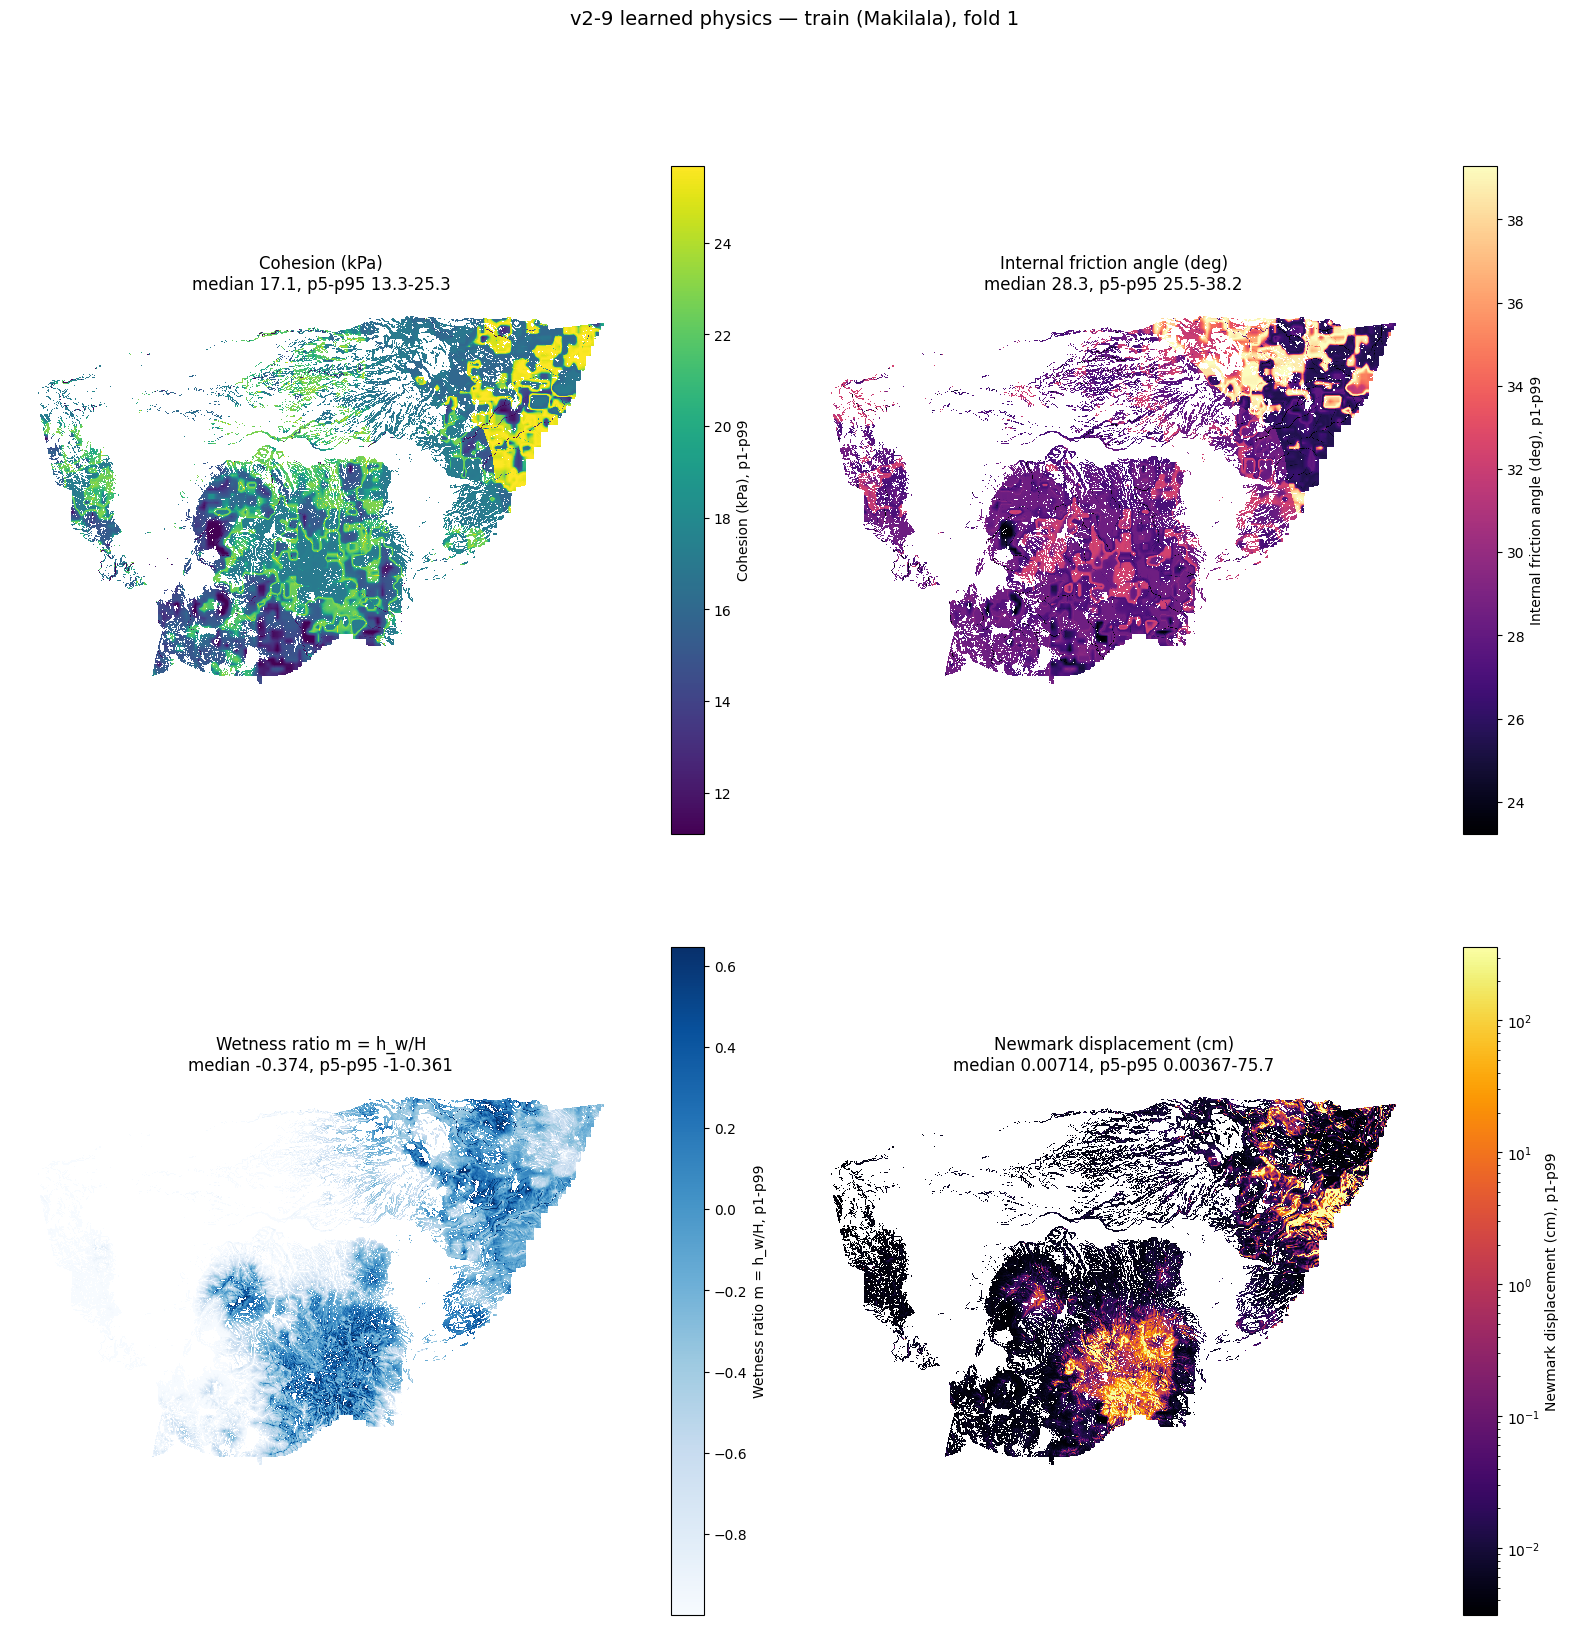

In [12]:
import matplotlib.colors as mcolors

MAP_FOLD = 1
MAP_AREA = "train (Makilala)"
# layer name -> (label, colormap, unit conversion, log colour scale)
MAP_LAYERS = {
    "cohesion_layer": ("Cohesion (kPa)", "viridis", lambda v: v, False),
    "internal_friction": ("Internal friction angle (deg)", "magma", np.degrees, False),
    "m_clip": ("Wetness ratio m = h_w/H", "Blues", lambda v: v, False),
    "displacement_layer": ("Newmark displacement (cm)", "inferno", lambda v: v, True),
}


def physics_map(fold, frame):
    """The MAP_LAYERS outputs of one fold model, one row per cell of `frame`."""
    path = MODEL_SAVE_PATH / f"fold-{fold}-model-v3.keras"
    model = load_trained_model(str(path))
    extractor = Model(model.inputs, {name: model.get_layer(name).output for name in MAP_LAYERS})
    feed = build_model_inputs(
        replay_transforms(frame, model, find_transforms_manifest(str(path))), model, pga_col=PGA_COL,
    )
    if len(feed) != len(frame):
        raise ValueError(f"{len(feed):,} model rows vs {len(frame):,} cells — rows no longer line up")
    raw = extractor.predict(dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=8192), verbose=0)
    values = {
        name: convert(np.asarray(raw[name]).reshape(len(feed), -1)[:, 0])
        for name, (_, _, convert, _) in MAP_LAYERS.items()
    }
    values["landslide"] = frame["landslide"].to_numpy().astype(int)
    return gpd.GeoDataFrame(values, geometry=frame.geometry.to_numpy(), crs=frame.crs), model


physics_gdf, map_model = physics_map(MAP_FOLD, AREAS[MAP_AREA])
threshold = map_model.get_layer("physics_prob")
if hasattr(threshold, "critical_displacement_cm"):
    print(f"Learned Newmark threshold: D0 = {threshold.critical_displacement_cm:.2f} cm, slope a = {threshold.slope:.2f}")

n_rows = int(np.ceil(len(MAP_LAYERS) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 9 * n_rows), sharex=True, sharey=True)
for ax, (name, (label, cmap, _, is_log)) in zip(axes.flat, MAP_LAYERS.items()):
    values = physics_gdf[name].to_numpy()
    lo, hi = np.percentile(values, [1, 99])
    norm = mcolors.LogNorm(vmin=max(lo, 1e-3), vmax=hi) if is_log else mcolors.Normalize(vmin=lo, vmax=hi)
    physics_gdf.plot(column=name, cmap=cmap, norm=norm, ax=ax, edgecolor="none", antialiased=False)
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, shrink=0.7, label=f"{label}, p1-p99")
    ax.set_title(f"{label}\nmedian {np.median(values):.3g}, p5-p95 {np.percentile(values, 5):.3g}-{np.percentile(values, 95):.3g}")
    ax.set_axis_off()
fig.suptitle(f"v2-9 learned physics — {MAP_AREA}, fold {MAP_FOLD}", fontsize=14)
fig.tight_layout()
fig.savefig(MODEL_SAVE_PATH / f"physics_maps_fold{MAP_FOLD}.png", dpi=200, bbox_inches="tight")
plt.show()


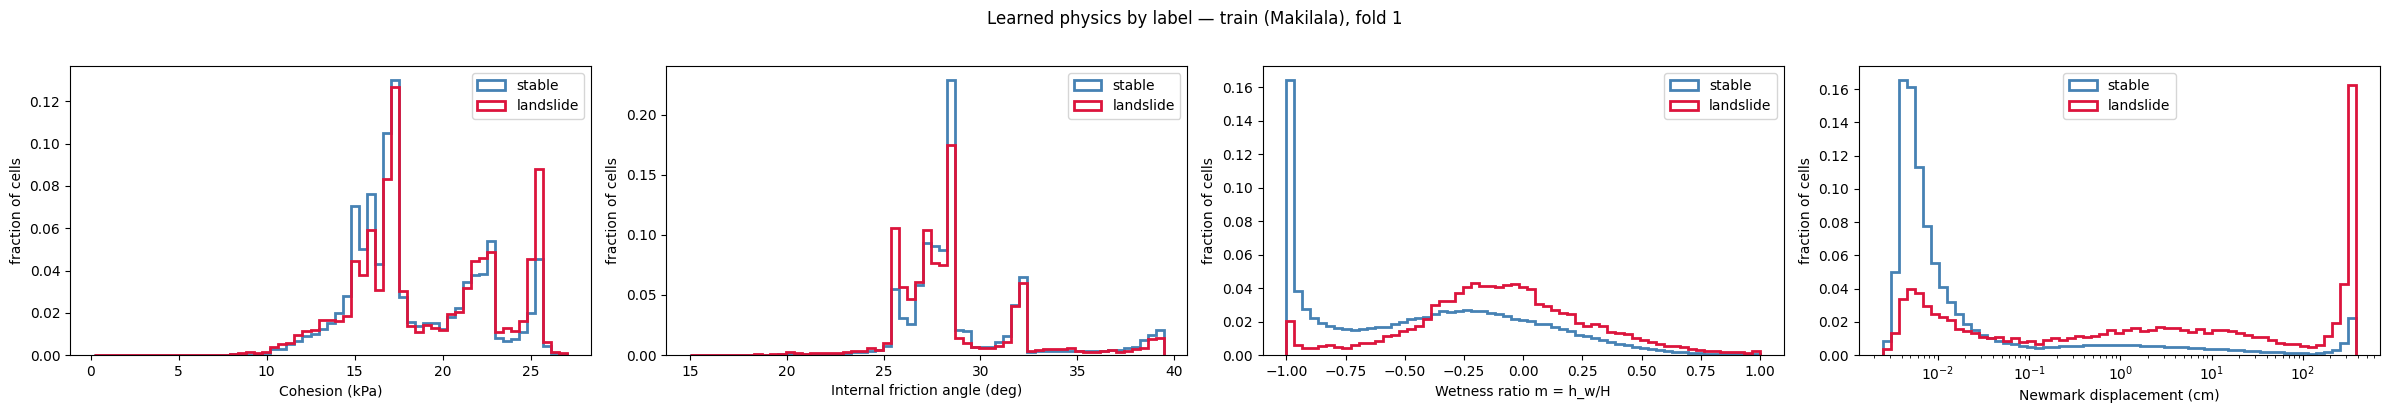

In [13]:
# Same outputs, landslide vs stable cells. Each group sums to 1, so the 5% landslide
# class is visible; fractions (not densities) keep the log-binned displacement readable.
fig, axes = plt.subplots(1, len(MAP_LAYERS), figsize=(6 * len(MAP_LAYERS), 4))
for ax, (name, (label, _, _, is_log)) in zip(axes, MAP_LAYERS.items()):
    values = physics_gdf[name].to_numpy()
    bins = (np.logspace(np.log10(max(values.min(), 1e-3)), np.log10(values.max()), 60)
            if is_log else np.linspace(values.min(), values.max(), 60))
    for flag, colour, group in ((0, "steelblue", "stable"), (1, "crimson", "landslide")):
        group_values = values[physics_gdf["landslide"] == flag]
        ax.hist(group_values, bins=bins, weights=np.full(len(group_values), 1 / len(group_values)),
                histtype="step", linewidth=2, color=colour, label=group)
    if is_log:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("fraction of cells")
    ax.legend()
fig.suptitle(f"Learned physics by label — {MAP_AREA}, fold {MAP_FOLD}", y=1.02)
fig.tight_layout()
plt.show()


## 5. Inference on the whole North Cotabato grid (`nc_mapped.gpkg`)

Runs the v2-9 fold models over all 9.4 M cells of `nc_mapped.gpkg`. The file is read in
chunks of `NC_CHUNK_ROWS` (`load_and_preprocess(rows=...)`; preprocessing is row-wise, so
chunks give the same rows as one load), each fold replays its own transform manifest, and
the results are written to one multi-band 25 m GeoTIFF, `nc_mapped_v2-9.tif` in
`MODEL_SAVE_PATH`:

| band | value |
|---|---|
| 1 `susceptibility_mean` | mean `final_head` over `NC_FOLDS` |
| 2 `susceptibility_std` | spread across folds (ensemble uncertainty) |
| 3 `cohesion_kpa` | fold-mean cohesion |
| 4 `friction_deg` | fold-mean friction angle |
| 5 `displacement_cm` | fold-mean Newmark displacement |
| 6 `wetness_m` | fold-mean wetness ratio m = h_w/H |
| 7 `fos` | fold-mean factor of safety |

Cells dropped by preprocessing (slope < 10°, missing inputs, `BUK_mean` = 0) are nodata.
Needs cells 1, 4 and the imports/helpers of section 3's first cell. `NC_FOLDS = [MAP_FOLD]`
runs a single fold instead of the ensemble.


In [20]:
import contextlib
import io

import pyogrio
from rasterio.transform import from_origin

NC_PATH = PROJECT_ROOT / "datasets/nc_mapped.gpkg"
NC_FOLDS = [1, 2, 3, 4, 5]
NC_CHUNK_ROWS = 500_000
NC_TIF = MODEL_SAVE_PATH / "nc_mapped_v2-9.tif"
NC_NODATA = -9999.0
# output -> (model layer, unit conversion)
NC_LAYERS = {
    "susceptibility": ("final_head", lambda v: v),
    "cohesion_kpa": ("cohesion_layer", lambda v: v),
    "friction_deg": ("internal_friction", np.degrees),
    "displacement_cm": ("displacement_layer", lambda v: v),
    "wetness_m": ("m_clip", lambda v: v),
    # Needs checkpoints trained after the fos_sink change in LandslideRainfall_v3.py;
    # older v2-9 models have no fos_layer (Keras pruned it).
    "fos": ("fos_layer", lambda v: v),
}


def load_fold_models(folds):
    """(model, extractor, manifest path) per fold; loaded once, reused for every chunk."""
    fold_models = []
    for fold in folds:
        path = MODEL_SAVE_PATH / f"fold-{fold}-model-v3.keras"
        model = load_trained_model(str(path))
        extractor = Model(model.inputs, {layer: model.get_layer(layer).output for layer, _ in NC_LAYERS.values()})
        fold_models.append((model, extractor, find_transforms_manifest(str(path))))
    return fold_models


def predict_chunk(frame, fold_models):
    """{output: array (n_folds, n_cells)} for one preprocessed chunk."""
    per_fold = {name: [] for name in NC_LAYERS}
    for model, extractor, manifest in fold_models:
        feed = build_model_inputs(replay_transforms(frame, model, manifest), model, pga_col=PGA_COL)
        if len(feed) != len(frame):
            raise ValueError(f"{len(feed):,} model rows vs {len(frame):,} cells — rows no longer line up")
        raw = extractor.predict(dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=8192), verbose=0)
        for name, (layer, convert) in NC_LAYERS.items():
            per_fold[name].append(convert(np.asarray(raw[layer]).reshape(len(feed), -1)[:, 0]))
    return {name: np.stack(values) for name, values in per_fold.items()}


def grid_index(frame, x0, y1):
    """Row / column of each 25 m cell in a raster whose top-left corner is (x0, y1)."""
    bounds = frame.geometry.bounds
    cols = np.rint((bounds["minx"].to_numpy() - x0) / GRID_CELL_M).astype(int)
    rows = np.rint((y1 - bounds["maxy"].to_numpy()) / GRID_CELL_M).astype(int)
    return rows, cols


def write_geotiff(path, bands, x0, y1, crs):
    first = next(iter(bands.values()))
    profile = dict(
        driver="GTiff", height=first.shape[0], width=first.shape[1], count=len(bands),
        dtype="float32", crs=crs, transform=from_origin(x0, y1, GRID_CELL_M, GRID_CELL_M),
        nodata=NC_NODATA, compress="deflate", tiled=True,
    )
    with rasterio.open(path, "w", **profile) as dst:
        for band, (name, values) in enumerate(bands.items(), start=1):
            dst.write(np.where(np.isnan(values), NC_NODATA, values).astype("float32"), band)
            dst.set_band_description(band, name)


nc_info = pyogrio.read_info(NC_PATH, force_total_bounds=True)
nc_x0, nc_y0, nc_x1, nc_y1 = nc_info["total_bounds"]
nc_shape = (int(round((nc_y1 - nc_y0) / GRID_CELL_M)), int(round((nc_x1 - nc_x0) / GRID_CELL_M)))
nc_bands = {
    name: np.full(nc_shape, np.nan, dtype="float32")
    for name in ("susceptibility_mean", "susceptibility_std", "cohesion_kpa", "friction_deg", "displacement_cm",
                 "wetness_m", "fos")
}
nc_fold_models = load_fold_models(NC_FOLDS)
n_features, n_predicted = nc_info["features"], 0

displacement = np.array([])

for start in range(0, n_features, NC_CHUNK_ROWS):
    # The loaders print per call; keep the log for the first chunk only.
    quiet = contextlib.redirect_stdout(io.StringIO()) if start else contextlib.nullcontext()
    with quiet:
        chunk, _, _ = load_and_preprocess(str(NC_PATH), rows=slice(start, start + NC_CHUNK_ROWS))
        chunk = chunk[chunk["BUK_mean"] > 0]
        if chunk.empty:
            continue
        stacked = predict_chunk(chunk, nc_fold_models)
    rows, cols = grid_index(chunk, nc_x0, nc_y1)
    nc_bands["susceptibility_mean"][rows, cols] = stacked["susceptibility"].mean(axis=0)
    nc_bands["susceptibility_std"][rows, cols] = stacked["susceptibility"].std(axis=0)
    for name in ("cohesion_kpa", "friction_deg", "displacement_cm", "wetness_m", "fos"):
        if name == "displacement_cm":
            displacement = np.concatenate([displacement, stacked[name].mean(axis=0)])
        nc_bands[name][rows, cols] = stacked[name].mean(axis=0)
    n_predicted += len(chunk)
    print(f"rows {start:,}-{min(start + NC_CHUNK_ROWS, n_features):,}: {len(chunk):,} cells predicted "
          f"({n_predicted:,} so far)")


write_geotiff(NC_TIF, nc_bands, nc_x0, nc_y1, nc_info["crs"])
print(f"\n{n_predicted:,} of {n_features:,} cells predicted with folds {NC_FOLDS} -> {NC_TIF}")


  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2386, PGA2_max_was_imputed=0.0000
  Categorical 'type': 70.8% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']
  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/r_t_ratio/soil_conditioned_v2-9/v1_cotabato_transforms_fold2.json (v1_cotabato_fold2): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mea

(4024, 4217)
(3966521,)
0.0022548548877239227 387.7356872558594 0.005059540271759033 21.7260256532319
Mean fraction of zeros: 0.792835081422738


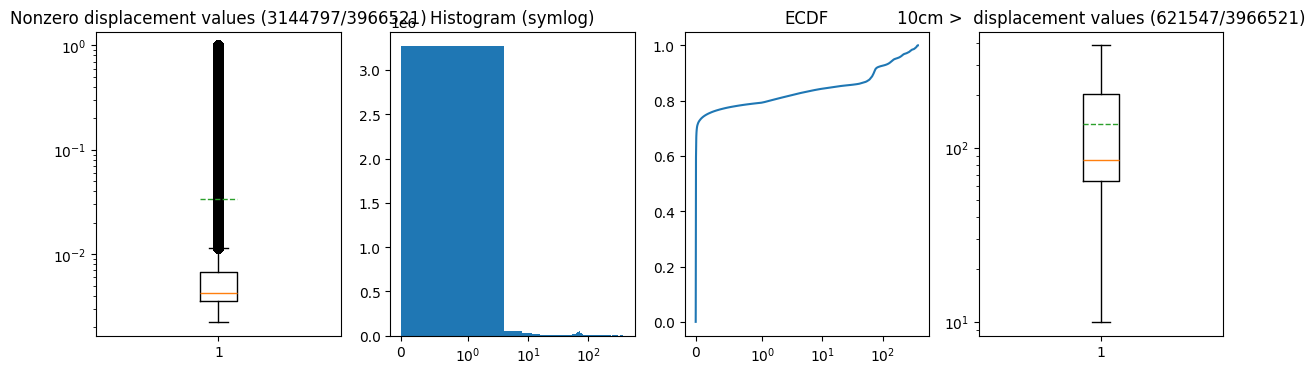

In [40]:
from matplotlib import pyplot as plt
print(nc_bands["displacement_cm"].shape)
print(displacement.shape)

print(displacement.min(), displacement.max(), np.median(displacement), np.mean(displacement))
print(f"Mean fraction of zeros: {((displacement > 0) & (displacement < 1)).mean()}")               # fraction of zeros

x = displacement
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

# 1. Boxplot of the nonzero part only (report the zero fraction separately)
nz = x[(x > 0) & (x < 1)]
axes[0].boxplot(nz, showmeans=True, meanline=True)
axes[0].set_yscale("log")
axes[0].set_title(f"Nonzero displacement values ({len(nz)}/{len(x)})")

nx = x[(x > 10)]
axes[3].boxplot(nx, showmeans=True, meanline=True)
axes[3].set_yscale("log")
axes[3].set_title(f"10cm >  displacement values ({len(nx)}/{len(x)})")

# 2. Histogram with symlog x-axis (handles the zeros)
axes[1].hist(x, bins=100)
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set_title("Histogram (symlog)")

# 3. ECDF: shows the spike at 0 and the tail clearly
xs = np.sort(x)
axes[2].plot(xs, np.arange(1, len(xs) + 1) / len(xs))
axes[2].set_xscale("symlog", linthresh=1)
axes[2].set_title("ECDF")
plt.tight_layout()


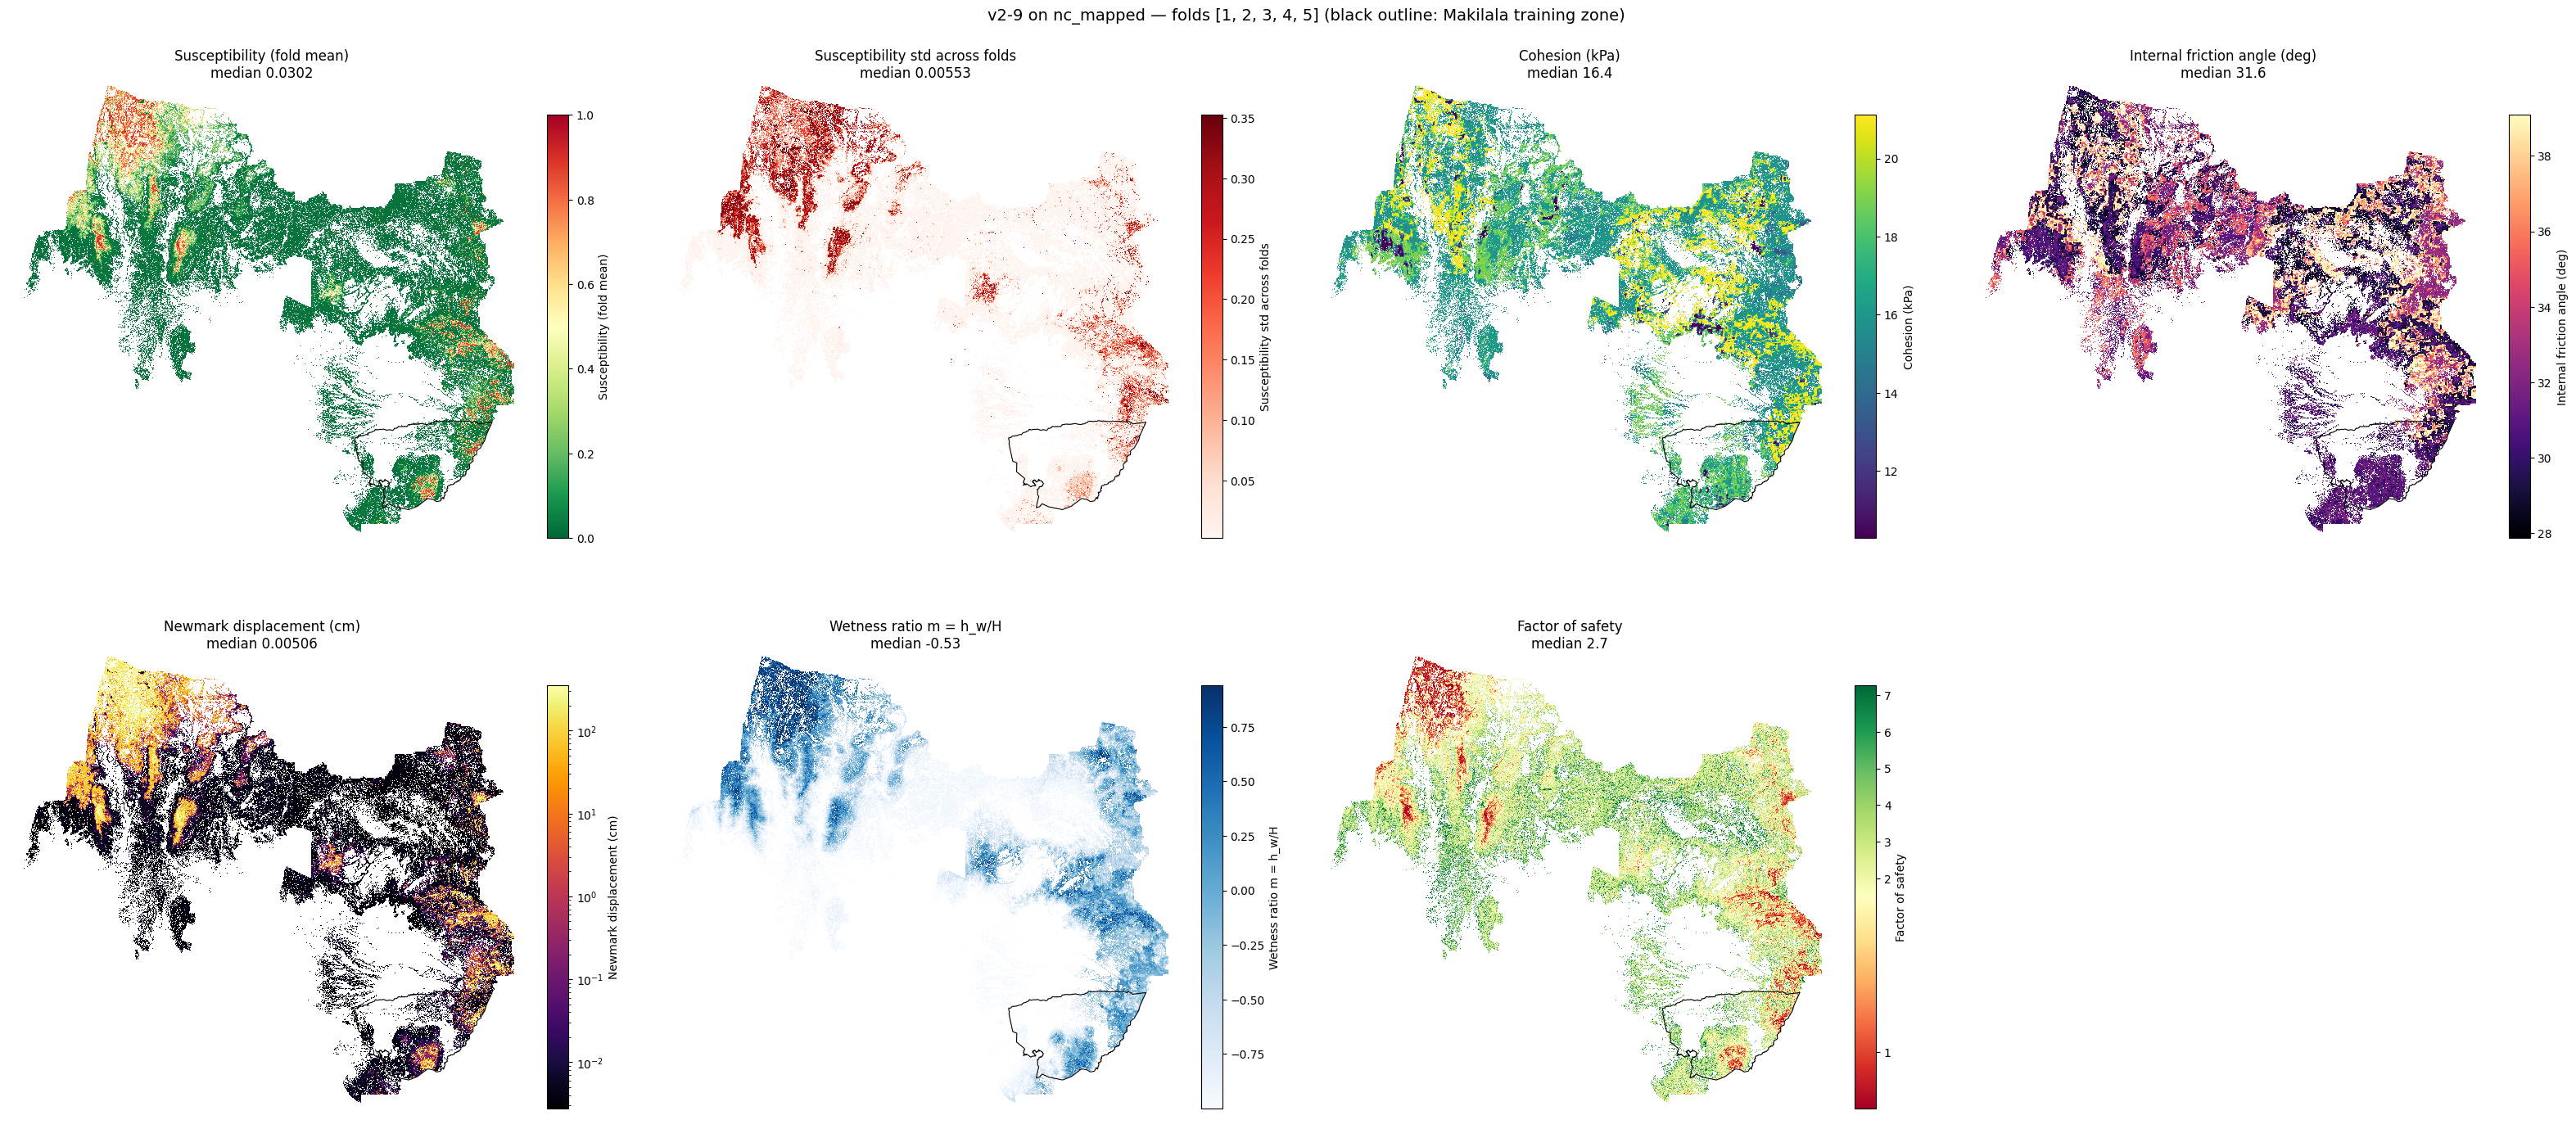

In [41]:
# Preview of the GeoTIFF bands (every 2nd pixel), Makilala training zone outlined.
FOS_STABLE = 1.5  # FOS colour midpoint: red below, green above
NC_PANELS = {
    "susceptibility_mean": ("Susceptibility (fold mean)", "RdYlGn_r", mcolors.Normalize(0, 1)),
    "susceptibility_std": ("Susceptibility std across folds", "Reds", None),
    "cohesion_kpa": ("Cohesion (kPa)", "viridis", None),
    "friction_deg": ("Internal friction angle (deg)", "magma", None),
    "displacement_cm": ("Newmark displacement (cm)", "inferno", "log"),
    "wetness_m": ("Wetness ratio m = h_w/H", "Blues", None),
    "fos": ("Factor of safety", "RdYlGn", "fos"),
}
extent = (nc_x0, nc_x0 + nc_shape[1] * GRID_CELL_M, nc_y1 - nc_shape[0] * GRID_CELL_M, nc_y1)
training_zone = gpd.read_file(TRAINING_ROI_PATH).to_crs(nc_info["crs"])

fig, axes = plt.subplots(2, 4, figsize=(32, 15))
for ax, (name, (label, cmap, norm)) in zip(axes.flat, NC_PANELS.items()):
    values = nc_bands[name][::2, ::2]
    lo, hi = np.nanpercentile(values, [1, 99])
    if norm == "log":
        norm = mcolors.LogNorm(vmin=max(lo, 1e-3), vmax=hi)
    elif norm == "fos":
        # Red below FOS_STABLE (unstable), green above, when the range straddles it.
        norm = (mcolors.TwoSlopeNorm(vmin=lo, vcenter=FOS_STABLE, vmax=hi) if lo < FOS_STABLE < hi
                else mcolors.Normalize(vmin=lo, vmax=hi))
    elif norm is None:
        norm = mcolors.Normalize(vmin=lo, vmax=hi)
    image = ax.imshow(values, extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    training_zone.boundary.plot(ax=ax, color="black", linewidth=0.8)
    fig.colorbar(image, ax=ax, shrink=0.7, label=label)
    ax.set_title(f"{label}\nmedian {np.nanmedian(nc_bands[name]):.3g}")
    ax.set_axis_off()
for ax in axes.flat[len(NC_PANELS):]:
    ax.set_visible(False)
fig.suptitle(f"v2-9 on nc_mapped — folds {NC_FOLDS} (black outline: Makilala training zone)", fontsize=14)
fig.tight_layout()
fig.savefig(MODEL_SAVE_PATH / "nc_mapped_v2-9_preview.png", dpi=200, bbox_inches="tight")
plt.show()
